In [ ]:
import pandas as pd

# Load cleaned dataset from the root directory path
df = pd.read_csv("/Telco_SQL_Ready.csv",
                 encoding="utf-8-sig")

In [ ]:

# =====================================================
# PYTHON CHECK 01: DATASET IMPORT AND VALIDATION
# Stage: 6.1 - Google Colab
# Purpose: Verify dataset and customer counts
# =====================================================


# Validate records and columns
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# Validate customer IDs
print("Unique customer IDs:", df["customerID"].nunique())

# Check churn distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

# Preview dataset
display(df.head())


Total rows: 7043
Total columns: 21
Unique customer IDs: 7043

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn,TotalCharges_Clean
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,No,1889.50
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,Yes,108.15
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,No,1840.75
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes,151.65


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

# =====================================================
# PYTHON CHECK 02: CUSTOMER CHURN PROFILE COMPARISON
# Stage: 6.2 - Exploratory Data Analysis
# Purpose: Compare tenure and monthly charges
#          between churned and non-churned customers
# =====================================================

churn_profile = df.groupby("Churn").agg(
    total_customers=("customerID", "count"),
    average_tenure=("tenure", "mean"),
    median_tenure=("tenure", "median"),
    average_monthly_charges=("MonthlyCharges", "mean"),
    median_monthly_charges=("MonthlyCharges", "median")
).round(2)

display(churn_profile)


,total_customers,average_tenure,median_tenure,average_monthly_charges,median_monthly_charges
Churn,,,,,
No,5174,37.57,38.0,61.27,64.43
Yes,1869,17.98,10.0,74.44,79.65


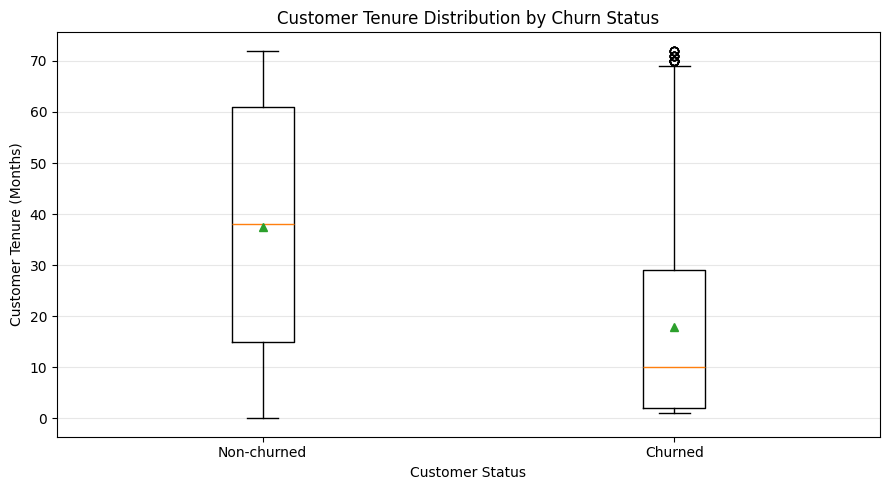

In [ ]:

# =====================================================
# PYTHON CHECK 03: TENURE DISTRIBUTION BY CHURN STATUS
# Stage: 6.3 - Exploratory Data Visualization
# Purpose: Compare the distribution of customer tenure
#          between churned and non-churned customers
# =====================================================

import matplotlib.pyplot as plt

# Separate customers by churn status
retained_tenure = df.loc[
    df["Churn"] == "No", "tenure"
].dropna()

churned_tenure = df.loc[
    df["Churn"] == "Yes", "tenure"
].dropna()

# Create box plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [retained_tenure, churned_tenure],
    tick_labels=["Non-churned", "Churned"],
    showmeans=True
)

# Add professional chart labels
ax.set_title("Customer Tenure Distribution by Churn Status")
ax.set_ylabel("Customer Tenure (Months)")
ax.set_xlabel("Customer Status")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# =====================================================
# PYTHON CHECK 04: MANN-WHITNEY U TEST
# Stage: 6.4 - Statistical Significance Testing
# Purpose: Test whether customer tenure distributions
# differ between churned and non-churned customers
# Hypothesis: H2 - Shorter tenure is associated
#             with customer churn
# =====================================================

from scipy.stats import mannwhitneyu

# Separate the two customer groups
churned = df.loc[
    df["Churn"] == "Yes", "tenure"
].dropna()

non_churned = df.loc[
    df["Churn"] == "No", "tenure"
].dropna()

# Perform two-sided Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    churned,
    non_churned,
    alternative="two-sided"
)

# Calculate rank-biserial effect size
effect_size = (
    2 * u_statistic /
    (len(churned) * len(non_churned))
) - 1

# Display results
print("PYTHON CHECK 04: TENURE STATISTICAL TEST")
print("----------------------------------------")
print(f"Churned customers: {len(churned)}")
print(f"Non-churned customers: {len(non_churned)}")
print(f"U statistic: {u_statistic:.2f}")
print(f"P-value: {p_value:.3e}")
print(f"Rank-biserial effect size: {effect_size:.4f}")


PYTHON CHECK 04: TENURE STATISTICAL TEST
----------------------------------------
Churned customers: 1869
Non-churned customers: 5174
U statistic: 2515538.00
P-value: 2.420e-208
Rank-biserial effect size: -0.4797


In [ ]:

# =====================================================
# PYTHON CHECK 05: MONTHLY CHARGES STATISTICAL TEST
# Stage: 6.5 - Statistical Significance Testing
# Purpose: Compare monthly charge distributions
#          between churned and non-churned customers
# Hypothesis: H3 - Higher charges are associated
#             with customer churn
# Method: Two-sided Mann-Whitney U test
# =====================================================

from scipy.stats import mannwhitneyu

# Separate monthly charges by churn status
churned_charges = df.loc[
    df["Churn"] == "Yes", "MonthlyCharges"
].dropna()

non_churned_charges = df.loc[
    df["Churn"] == "No", "MonthlyCharges"
].dropna()

# Perform statistical test
u_statistic, p_value = mannwhitneyu(
    churned_charges,
    non_churned_charges,
    alternative="two-sided",
    method="asymptotic"
)

# Calculate rank-biserial effect size
effect_size = (
    2 * u_statistic /
    (len(churned_charges) * len(non_churned_charges))
) - 1

# Display results
print("PYTHON CHECK 05: MONTHLY CHARGES TEST")
print("------------------------------------")
print(f"Churned customers: {len(churned_charges)}")
print(f"Non-churned customers: {len(non_churned_charges)}")

print(f"Median charges - Churned: {churned_charges.median():.2f}")
print(f"Median charges - Non-churned: {non_churned_charges.median():.2f}")

print(f"U statistic: {u_statistic:.2f}")
print(f"P-value: {p_value:.3e}")
print(f"Rank-biserial effect size: {effect_size:.4f}")


PYTHON CHECK 05: MONTHLY CHARGES TEST
------------------------------------
Churned customers: 1869
Non-churned customers: 5174
Median charges - Churned: 79.65
Median charges - Non-churned: 64.43
U statistic: 6003125.50
P-value: 3.312e-54
Rank-biserial effect size: 0.2416


In [ ]:

# =====================================================
# PYTHON CHECK 06: CHI-SQUARE TEST - CONTRACT AND CHURN
# Stage: 6.6 - Categorical Statistical Analysis
# Purpose: Test association between contract type
#          and customer churn status
# Hypothesis: H1 - Month-to-month customers exhibit
#             higher churn rates than longer contracts
# Method: Chi-square test of independence
# =====================================================

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Create contract vs churn contingency table
contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("CONTRACT TYPE VS CHURN")
display(contract_table)

# Perform chi-square test
chi2, p_value, degrees_freedom, expected = chi2_contingency(
    contract_table
)

# Calculate Cramer's V effect size
n = contract_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(contract_table.shape) - 1))
)

# Display statistical results
print("\nPYTHON CHECK 06: CHI-SQUARE TEST")
print("--------------------------------")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.3e}")
print(f"Degrees of freedom: {degrees_freedom}")
print(f"Cramer's V effect size: {cramers_v:.4f}")
print(f"Minimum expected cell count: {expected.min():.2f}")


CONTRACT TYPE VS CHURN


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



PYTHON CHECK 06: CHI-SQUARE TEST
--------------------------------
Chi-square statistic: 1184.5966
P-value: 5.863e-258
Degrees of freedom: 2
Cramer's V effect size: 0.4101
Minimum expected cell count: 390.89


In [ ]:

# =====================================================
# PYTHON CHECK 07: MODEL DATA PREPARATION
# Stage: 6.7 - Multivariable Churn Analysis
# Purpose: Prepare predictors, binary churn target
#          and stratified training/testing datasets
# =====================================================

from sklearn.model_selection import train_test_split

# Select variables for the first model
features = ["Contract", "tenure", "MonthlyCharges"]

X = df[features].copy()

# Convert target to binary: Yes = 1, No = 0
y = df["Churn"].map({"Yes": 1, "No": 0})

# Check for missing values
print("Missing predictor values:")
print(X.isna().sum())

print("\nMissing target values:", y.isna().sum())

# Divide data into training and testing groups
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("\nMODEL DATASET SIZES")
print("-------------------")
print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

# Check churn proportions
print("\nTraining churn proportion:",
      round(y_train.mean() * 100, 2), "%")

print("Testing churn proportion:",
      round(y_test.mean() * 100, 2), "%")

# Preview training data
print("\nTraining data preview:")
display(X_train.head())


Missing predictor values:
Contract          0
tenure            0
MonthlyCharges    0
dtype: int64

Missing target values: 0

MODEL DATASET SIZES
-------------------
Training customers: 5634
Testing customers: 1409

Training churn proportion: 26.54 %
Testing churn proportion: 26.54 %

Training data preview:


,Contract,tenure,MonthlyCharges
3738,Month-to-month,35,49.20
3151,Month-to-month,15,75.10
4860,Two year,13,40.55
3867,Two year,26,73.50
3810,Month-to-month,1,44.55


In [ ]:

# =====================================================
# PYTHON CHECK 08: LOGISTIC REGRESSION MODEL
# Stage: 6.8 - Multivariable Churn Analysis
# Purpose: Fit an interpretable churn model using
#          contract type, tenure and monthly charges
# Method: Logistic Regression
# =====================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# 1. Prepare categorical and numerical variables
preprocessor = ColumnTransformer(
    transformers=[
        (
            "contract",
            OneHotEncoder(
                categories=[[
                    "Two year",
                    "One year",
                    "Month-to-month"
                ]],
                drop="first",
                handle_unknown="ignore"
            ),
            ["Contract"]
        ),
        (
            "numeric",
            StandardScaler(),
            ["tenure", "MonthlyCharges"]
        )
    ]
)

# 2. Build the model pipeline
churn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("logistic_regression", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# 3. Train using training data only
churn_model.fit(X_train, y_train)

# 4. Extract the coefficients
coefficients = churn_model.named_steps[
    "logistic_regression"
].coef_[0]

# Get numerical scaling values
scales = churn_model.named_steps[
    "preprocessing"
].named_transformers_["numeric"].scale_

# 5. Calculate interpretable odds ratios
results = pd.DataFrame({
    "Variable": [
        "One year vs Two year",
        "Month-to-month vs Two year",
        "Tenure (+12 months)",
        "MonthlyCharges (+10 units)"
    ],
    "Odds Ratio": [
        np.exp(coefficients[0]),
        np.exp(coefficients[1]),
        np.exp(coefficients[2] * 12 / scales[0]),
        np.exp(coefficients[3] * 10 / scales[1])
    ]
})

# 6. Display results
print("PYTHON CHECK 08: LOGISTIC REGRESSION")
print("-----------------------------------")
print("Model trained successfully")
print("Training records:", len(X_train))
print("Variables used: Contract, tenure, MonthlyCharges")

print("\nADJUSTED ODDS RATIOS")
display(results.round(4))


PYTHON CHECK 08: LOGISTIC REGRESSION
-----------------------------------
Model trained successfully
Training records: 5634
Variables used: Contract, tenure, MonthlyCharges

ADJUSTED ODDS RATIOS


,Variable,Odds Ratio
0,One year vs Two year,2.3573
1,Month-to-month vs Two year,7.0967
2,Tenure (+12 months),0.6579
3,MonthlyCharges (+10 units),1.3369


In [ ]:

# =====================================================
# PYTHON CHECK 09: LOGISTIC REGRESSION MODEL EVALUATION
# Stage: 6.9 - Model Performance Assessment
# Purpose: Evaluate predictions on held-out test data
# Business question: How reliably does the model
# identify customers recorded as churned?
# =====================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Predict churn using the held-out test data
y_pred = churn_model.predict(X_test)

# 2. Predict probability of churn
y_prob = churn_model.predict_proba(X_test)[:, 1]

# 3. Calculate model performance
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

# 4. Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

# 5. Calculate simple baseline accuracy
baseline_accuracy = (y_test == 0).mean()

# 6. Display results
print("PYTHON CHECK 09: MODEL EVALUATION")
print("---------------------------------")
print("Test customers:", len(y_test))

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

print(f"\nBaseline accuracy: {baseline_accuracy:.4f}")

print("\nCONFUSION MATRIX")
print("----------------")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


PYTHON CHECK 09: MODEL EVALUATION
---------------------------------
Test customers: 1409

Accuracy: 0.7771
Precision: 0.5980
Recall: 0.4893
F1-score: 0.5382
ROC-AUC: 0.8239

Baseline accuracy: 0.7346

CONFUSION MATRIX
----------------
True Negatives: 912
False Positives: 123
False Negatives: 191
True Positives: 183


PYTHON CHECK 10: PRECISION-RECALL ANALYSIS
------------------------------------------
Average Precision (AP): 0.5978
Baseline churn prevalence: 0.2654


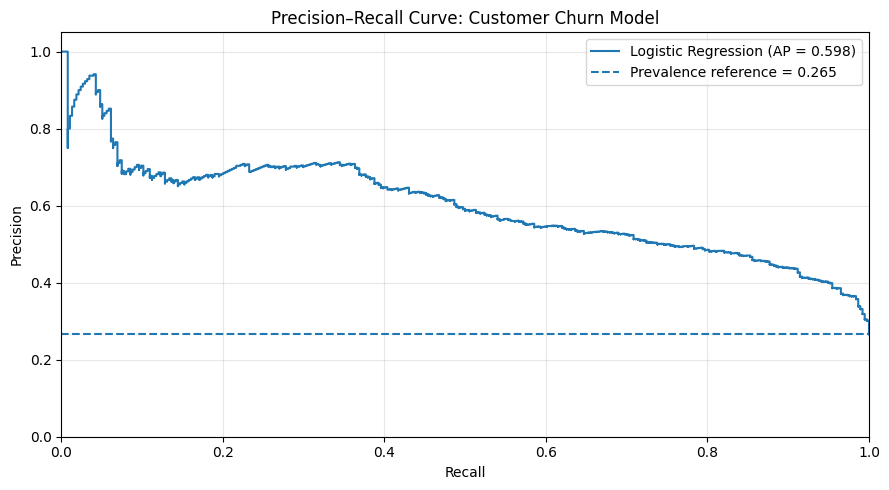

In [ ]:

# =====================================================
# PYTHON CHECK 10: PRECISION-RECALL CURVE
# Stage: 6.10 - Model Performance Diagnostics
# Purpose: Evaluate precision-recall trade-offs
#          and calculate Average Precision (AP)
# Business question: How well does the model rank
# customers recorded as churned?
# =====================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Use predictions from the held-out test dataset
precision_values, recall_values, thresholds = (
    precision_recall_curve(y_test, y_prob)
)

# Calculate Average Precision
average_precision = average_precision_score(
    y_test, y_prob
)

# Reference level: proportion of churned customers
baseline_precision = y_test.mean()

print("PYTHON CHECK 10: PRECISION-RECALL ANALYSIS")
print("------------------------------------------")
print(f"Average Precision (AP): {average_precision:.4f}")
print(f"Baseline churn prevalence: {baseline_precision:.4f}")

# Plot the Precision-Recall curve
plt.figure(figsize=(9, 5))

plt.step(
    recall_values,
    precision_values,
    where="post",
    label=f"Logistic Regression (AP = {average_precision:.3f})"
)

plt.axhline(
    y=baseline_precision,
    linestyle="--",
    label=f"Prevalence reference = {baseline_precision:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: Customer Churn Model")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# =====================================================
# PYTHON CHECK 11: CLASSIFICATION THRESHOLD COMPARISON
# Stage: 6.11 - Model Decision Threshold Analysis
# Purpose: Compare precision and recall at different
#          thresholds using training-data cross-validation
# Business question: Can we identify more churned
# customers without excessive false positives?
# =====================================================

import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# 1. Set up five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Generate out-of-fold predictions
# Uses training data only, not the test dataset
cv_probabilities = cross_val_predict(
    churn_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# 3. Compare three classification thresholds
threshold_results = []

for threshold in [0.30, 0.40, 0.50]:

    predictions = (
        cv_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Customers Flagged": int(predictions.sum()),
        "Precision": round(
            precision_score(
                y_train, predictions,
                zero_division=0
            ), 4
        ),
        "Recall": round(
            recall_score(
                y_train, predictions,
                zero_division=0
            ), 4
        ),
        "F1 Score": round(
            f1_score(
                y_train, predictions,
                zero_division=0
            ), 4
        )
    })

# 4. Display comparison table
threshold_df = pd.DataFrame(threshold_results)

print("PYTHON CHECK 11: THRESHOLD COMPARISON")
print("-------------------------------------")
print("Method: 5-fold cross-validation")
print("Dataset: Training records only")

display(threshold_df)


PYTHON CHECK 11: THRESHOLD COMPARISON
-------------------------------------
Method: 5-fold cross-validation
Dataset: Training records only


,Threshold,Customers Flagged,Precision,Recall,F1 Score
0,0.3,2200,0.5123,0.7538,0.6100
1,0.4,1732,0.5531,0.6408,0.5937
2,0.5,1165,0.6343,0.4943,0.5556


In [ ]:

# =====================================================
# PYTHON CHECK 12: HELD-OUT THRESHOLD EVALUATION
# Stage: 6.12 - Final Model Performance Assessment
# Purpose: Evaluate the preselected threshold of 0.40
#          on the reserved test dataset
# Business question: How well does the selected
# threshold identify churned customers on unseen data?
# =====================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Use the selected threshold from cross-validation
selected_threshold = 0.40

# 2. Predict using the held-out test probabilities
test_predictions = (
    y_prob >= selected_threshold
).astype(int)

# 3. Calculate performance
print("PYTHON CHECK 12: HELD-OUT TEST RESULTS")
print("-------------------------------------")
print("Selected threshold:", selected_threshold)
print("Test customers:", len(y_test))
print("Customers flagged:", test_predictions.sum())

print("\nMODEL PERFORMANCE")
print(
    "Accuracy:",
    round(accuracy_score(y_test, test_predictions), 4)
)
print(
    "Precision:",
    round(precision_score(y_test, test_predictions), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, test_predictions), 4)
)
print(
    "F1-score:",
    round(f1_score(y_test, test_predictions), 4)
)

# 4. Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

print("\nCONFUSION MATRIX")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


PYTHON CHECK 12: HELD-OUT TEST RESULTS
-------------------------------------
Selected threshold: 0.4
Test customers: 1409
Customers flagged: 443

MODEL PERFORMANCE
Accuracy: 0.758
Precision: 0.5372
Recall: 0.6364
F1-score: 0.5826

CONFUSION MATRIX
True Negatives: 830
False Positives: 205
False Negatives: 136
True Positives: 238


,Threshold,Precision,Recall,F1-score
0,0.50,59.80,48.93,53.82
1,0.40,53.72,63.64,58.26


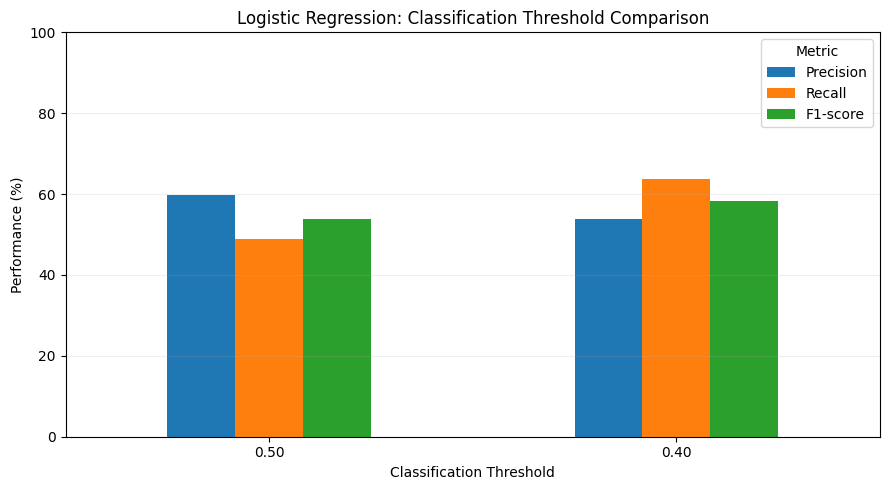

In [ ]:

# =====================================================
# PYTHON CHECK 13: FINAL MODEL PERFORMANCE VISUALIZATION
# Stage: 6.13 - Portfolio Visualization
# Purpose: Compare test-set performance at thresholds
#          0.50 and 0.40 using a professional chart
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Calculate results using the held-out test set
comparison = []

for threshold in [0.50, 0.40]:

    predictions = (y_prob >= threshold).astype(int)

    comparison.append({
        "Threshold": f"{threshold:.2f}",
        "Precision": precision_score(
            y_test, predictions
        ) * 100,
        "Recall": recall_score(
            y_test, predictions
        ) * 100,
        "F1-score": f1_score(
            y_test, predictions
        ) * 100
    })

comparison_df = pd.DataFrame(comparison)

# Display results
display(comparison_df.round(2))

# Create portfolio chart
ax = comparison_df.set_index("Threshold")[
    ["Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "Logistic Regression: Classification Threshold Comparison"
)
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 100)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save chart for portfolio use
plt.savefig(
    "threshold_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
